In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import spacy

# Load dataset
df = pd.read_csv("fakenews.csv")

# Load English NLP model
nlp = spacy.load("en_core_web_sm")

In [2]:
# Handle missing values
df["headline"] = df["headline"].fillna("").astype(str)
df["body_text"] = df["body_text"].fillna("").astype(str)

# Combine headline and body text
df["text"] = df["headline"] + " " + df["body_text"]

# Display dataset
print(df[["label", "text"]].head())

print("\nTotal articles:", len(df))

  label                                               text
0  Real  Global economy faces recession The Prime Minis...
1  Real  Earthquake hits Chittagong, panic spreads Gove...
2  Fake  Breakthrough in Bangladesh's tech industry Loc...
3  Fake  Dengue situation worsens in the country The Pr...
4  Real  New virus outbreak sparks fear Government sour...

Total articles: 2212


In [3]:
# Perform dependency parsing
dependency_records = []

for index, row in df.iterrows():
    doc = nlp(row["text"])

    for token in doc:
        if not token.is_space and not token.is_punct:
            dependency_records.append({
                "news_id": row["news_id"],
                "label": row["label"],
                "word": token.text,
                "POS_tag": token.pos_,
                "dependency": token.dep_,
                "head_word": token.head.text
            })

# Convert results into a DataFrame
dependency_df = pd.DataFrame(dependency_records)

# Display the first 20 results
print("Dependency Parsing Results:")
print(dependency_df.head(7))

Dependency Parsing Results:
   news_id label       word POS_tag dependency head_word
0        1  Real     Global     ADJ       amod   economy
1        1  Real    economy    NOUN      nsubj     faces
2        1  Real      faces    VERB       ROOT     faces
3        1  Real  recession    NOUN       dobj     faces
4        1  Real        The     DET        det  Minister
5        1  Real      Prime   PROPN   compound  Minister
6        1  Real   Minister   PROPN      nsubj  attended


In [4]:
# Analyze sentence complexity for each article
complexity_records = []

for index, row in df.iterrows():
    doc = nlp(row["text"])

    sentences = list(doc.sents)

    # Count words in each sentence
    sentence_lengths = [
        len([token for token in sent if not token.is_punct and not token.is_space])
        for sent in sentences
    ]

    # Count grammatical relationships
    dependency_counts = sum(
        1 for token in doc
        if token.dep_ not in ["ROOT", "punct", "space"]
    )

    complexity_records.append({
        "news_id": row["news_id"],
        "label": row["label"],
        "sentence_count": len(sentences),
        "word_count": len([
            token for token in doc
            if not token.is_punct and not token.is_space
        ]),
        "average_sentence_length": (
            sum(sentence_lengths) / len(sentence_lengths)
            if sentence_lengths else 0
        ),
        "dependency_count": dependency_counts
    })

# Convert results into a DataFrame
complexity_df = pd.DataFrame(complexity_records)

# Display the first five rows
print("Sentence Complexity Analysis:")
print(complexity_df.head())

Sentence Complexity Analysis:
   news_id label  sentence_count  word_count  average_sentence_length  \
0        1  Real               1          15                     15.0   
1        2  Real               1          16                     16.0   
2        3  Fake               1          15                     15.0   
3        4  Fake               1          17                     17.0   
4        5  Real               1          16                     16.0   

   dependency_count  
0                14  
1                15  
2                14  
3                16  
4                15  


In [5]:
# Compare complexity metrics by news label
complexity_comparison = complexity_df.groupby("label")[
    [
        "sentence_count",
        "word_count",
        "average_sentence_length",
        "dependency_count"
    ]
].mean()

# Display the comparison
print("Sentence Complexity: Real vs Fake News")
print(complexity_comparison.round(2))

Sentence Complexity: Real vs Fake News
       sentence_count  word_count  average_sentence_length  dependency_count
label                                                                       
Fake             1.24       15.65                    13.52             14.42
Real             1.22       15.48                    13.52             14.26


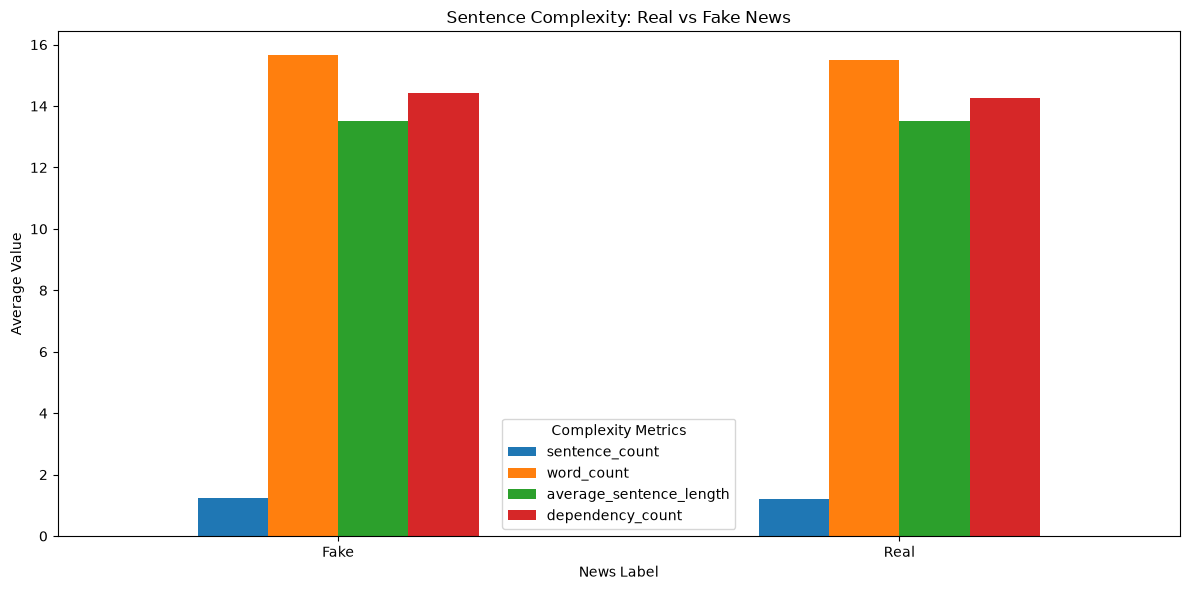

In [6]:

# Plot sentence complexity comparison
complexity_comparison.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Sentence Complexity: Real vs Fake News")
plt.xlabel("News Label")
plt.ylabel("Average Value")
plt.xticks(rotation=0)
plt.legend(title="Complexity Metrics")
plt.tight_layout()
plt.show()

Grammatical Relationships in Real vs Fake News:
dependency  ROOT  acl  acomp  advcl  advmod  amod  appos  attr  aux  auxpass  \
label                                                                          
Fake        1371  203    220     72     428  1580     33   123  640      228   
Real        1344  225    236     70     421  1582     35   109  650      190   

dependency  ...  npadvmod  nsubj  nsubjpass  oprd  pobj  poss  predet  prep  \
label       ...                                                               
Fake        ...       120   2622        218   110  1488   128     100  1488   
Real        ...       102   2655        186   106  1425    98     121  1425   

dependency  relcl  xcomp  
label                     
Fake           83    117  
Real           91    111  

[2 rows x 31 columns]


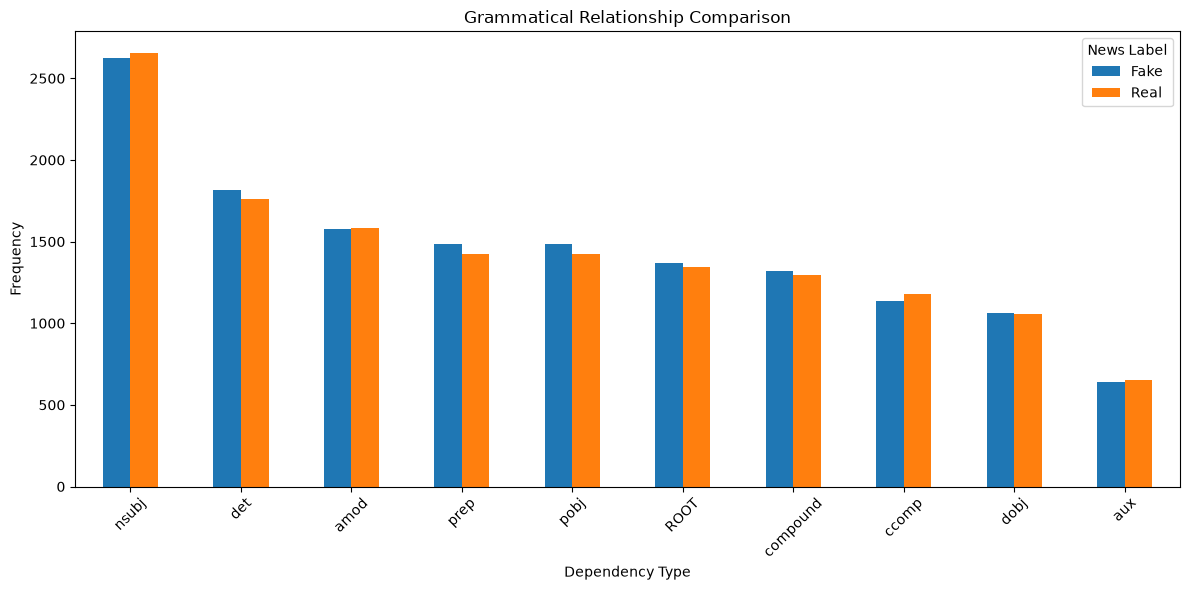

In [7]:
# Count grammatical dependencies by news label
dependency_comparison = dependency_df.groupby(
    ["label", "dependency"]
).size().unstack(fill_value=0)

# Display the most common grammatical relationships
print("Grammatical Relationships in Real vs Fake News:")
print(dependency_comparison)

# Select the 10 most common dependency types overall
top_dependencies = (
    dependency_df["dependency"]
    .value_counts()
    .head(10)
    .index
)

dependency_comparison[top_dependencies].T.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Grammatical Relationship Comparison")
plt.xlabel("Dependency Type")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.legend(title="News Label")
plt.tight_layout()
plt.show()


In [8]:
# Save dependency parsing results
dependency_df.to_csv(
    "T15_dependency_parsing.csv",
    index=False
)

# Save sentence complexity results
complexity_df.to_csv(
    "T15_sentence_complexity.csv",
    index=False
)

# Save Real vs Fake complexity comparison
complexity_comparison.to_csv(
    "T15_complexity_comparison.csv"
)

# Save grammatical relationship comparison
dependency_comparison.to_csv(
    "T15_grammatical_relationships.csv"
)

print("Task 15 completed successfully!")

print("\nFiles saved:")
print("1. T15_dependency_parsing.csv")
print("2. T15_sentence_complexity.csv")
print("3. T15_complexity_comparison.csv")
print("4. T15_grammatical_relationships.csv")

Task 15 completed successfully!

Files saved:
1. T15_dependency_parsing.csv
2. T15_sentence_complexity.csv
3. T15_complexity_comparison.csv
4. T15_grammatical_relationships.csv
